# Fundamentos de tensorflow

en este cuaderno vamos aprender:
1. Crear tensores
2. Obtener información de tensores
3. Manipular tensores
4. Jugar con numpy -> tensores
5. usar gpus (ya sabemos cosas)


# Tensor? Qué es eso?
Es un array multidimensional que puede formar parte de un grafo computacional, que nos ayudará a crear RNAs. De forma intuitiva podemos
pensar que un tensor es como un array de numpy pero con ciertas funcionalidades para trabajar con redes neuronales.
Con los tensores podemos representar prácticamente cualqueir cosa:
- números
- imagen: matriz bidimensional? ?? en realidad es tridimensional, hablando de forma , cómo sería de una imagen por ejemplo: [5222,3648,4]. Sí, los tensores también shape.
- Podría ser texto, pero de forma mucho más compleja a través de embeddings, que guardan el sentido semántico no sólo de una palabra,sino de un texto
- Cualquier otro tipo de información: coordenadas geográficas, telemetría...
La diferencia principal con numpy es que los tensores se pueden meter en la gpu y someterlos a ese gráfo computacional para "aprendizaje automático"


In [12]:
# saber la versión de tensorflow
import tensorflow as tf
print(tf.__version__)

2.21.0


In [13]:
#eliminar logs de C++, cuando usamos gpus
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # o "3" para solo errores


In [14]:
# comprobar el número de gpus disponibles
print(tf.config.list_physical_devices('GPU'))


[]


# Creación de tensores.
OJO: Normalmente, nosotros no crearemos tensores a no ser que sea para inferencia (predict)
 - Tensores constantes: (no cambian) tf.constant
 - Tensores variables: (sí cambian)  tf.Variable
tf.constant es un método por eso lleva la `c` en minúscula, mientras que tf.Variable es una clase.


In [15]:
# empezamos con tf.constant

# 1. creación de tensores escalares



In [16]:
# ver número de dimensiones (atributo ndim)


In [17]:
# crear un tensor constante de una dimensión



In [18]:
# crear un tensor de dos dimensiones:


In [19]:
# ver sus dimensiones

### los tensores tienen su tipo de datos interno:
Pueden ser tf.int32, tf.float32, tf.float64, tf.int8, tf.bool, tf.string


In [20]:
# crear un tensor multidimensional (3 dims) con formato interno tf.float32


In [21]:
# Crear tensores variables



In [22]:
# uso de assign_add([x,x,x])


# Semillas aleatorias en TensorFlow

Las semillas (*seeds*) permiten controlar la generación de números pseudoaleatorios para conseguir reproducibilidad en nuestros experimentos.

### 1. Semilla global (Global Seed)

Establece una semilla general para las operaciones aleatorias de TensorFlow.

```python
tf.random.set_seed(42)
```

### 2. Semilla local (Operation Seed)

Se establece directamente en una operación aleatoria concreta.

```python
tf.random.shuffle(tensor, seed=42)
```

Puede combinarse con una semilla global para controlar la secuencia de resultados.

### 3. Generador explícito (Generator)

Crea un generador independiente con su propio estado interno.

```python
generador = tf.random.Generator.from_seed(42)

tensor1 = generador.normal(shape=(3, 2))
tensor2 = generador.normal(shape=(3, 2))
```

Cada llamada avanza el estado interno y genera nuevos valores.

### Resumen

| Tipo | Función | Ámbito |
|---|---|---|
| Global | `tf.random.set_seed()` | General |
| Local | `seed=42` | Operación concreta |
| Generador | `tf.random.Generator.from_seed()` | Generador independiente |

**Importante:** las semillas permiten reproducir experimentos, aunque no garantizan resultados idénticos entre distintos dispositivos, versiones o entornos.

Para mejorar la reproducibilidad:

```python
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()
```



## Crear tensores aleatorios
vamos a utilizar las funciones tf.random.uniform y tf.random.normal
Podemos seleccionar la semilla con la que queremos generar esos números "pseudoaleatorios"
Las RNAs utilizan números aleatorios para inicializar pesos para luego aprender patrones

In [23]:
# semilla, se cambia con tf.random.Generator.from_seed(xx), con la funcion objeto.normal(forma)



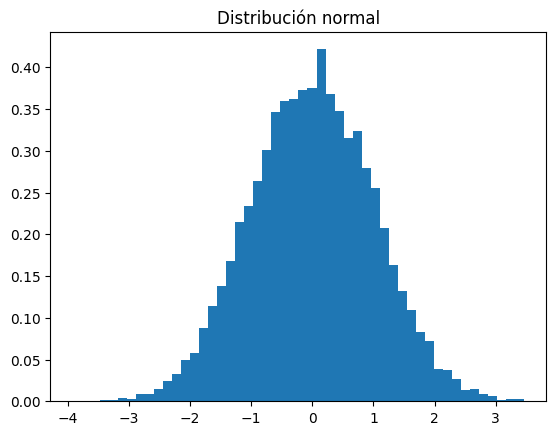

In [24]:
# observar forma de la distribución normal
import tensorflow as tf
import matplotlib.pyplot as plt

datos = tf.random.normal((10000,), mean=0, stddev=1)

plt.hist(datos.numpy(), bins=50, density=True)
plt.title("Distribución normal")
plt.show()


In [25]:
# distribución uniforme

In [26]:
# comparar tensores, son objeto1 y objeto2 iguales?



In [27]:
# mezclar con tf.random.shuffle

In [28]:
# crear tensores utilizando semilla "general"


In [29]:
# cambiar la semilla global

# cambiar la local


In [30]:
# Otras formas de crear tensores

# tf.ones


In [31]:
# tf.zeros


In [32]:
# Crear tensores a partir de arrays de numpy

import numpy as np

miVector = np.arange(1,25,dtype=np.int32)
miVector



array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24], dtype=int32)

In [33]:
# ¿Puedo poner la forma que me de la gana?
# NO -> Tienen que cuadrar el número de elementos,
# por ejemplo, si la forma es 2,4,3 -> 2*4*3 = 24 elementos



# Obtener información de los tensores
1. Valor (todos los elementos que forman parte del tensor)
2. Forma (Número de elementos de cada dimensión)
3. Longitud/Tamaño (size) (Número total de elementos)
4. Tipo de dato
5. Rango del tensor (Número de dimensiones)




In [34]:
# sacar toda la información del tensor A

# 1. valor


NameError: name 'A' is not defined

In [ ]:
# 2. forma


In [ ]:
# 3. longitud / tamaño (size)



In [ ]:
# entonces len(A) me da la longitud?? Depende de qué longitud busquemos
# es decir, si buscamos la longitud de la primera dimensión es 2



In [ ]:
# OBTENER DE OTRA MANERA la longitud de cada eje (cuánto mide cada dimensión)


In [ ]:
# reflexión sobre tema "EJES" -> En python, el eje representa una dimensión
# EJE 0 -> dimensión 0
# eje 1 -> dimensión 1
# eje 2...
# eje -1 -> la última dimensión conocida
# ... -> "Todas las dimensiones anteriores"

In [ ]:
# 4. tipo de datos


In [ ]:
# 5. Rango


# Utilizar la indexación para obtener _subtensores_
# Subtensor: una pequeña porción de un tensor

º

In [ ]:
Usar slicing para obtener subtensores: de los dos primeros elementos, dame solo las dos primeras filas y las dos primeras columnas

In [ ]:
# Dado este tensor
B = tf.constant([ [10,3,7],[3,2,4]])
#print(B)

# quiero el último elemento de cada fila


## Ampliación de dimensiones
Puedo ampliar la dimensión de un tensor utilizando tf.newaxis, por ejemplo:




In [ ]:
# esto es equivalente a utilizar expand_dims


In [ ]:
# añadir una por la primera dimensión


# Manipular tensores (operaciones)
Las operaciones básicas son +, -, *

In [ ]:
# sumar valores a un tensor


# también se puede restar


In [ ]:
# multiplicar con * o con multiply


In [ ]:
# estas operaciones producen un nuevo tensor, NO MODIFICAN el original


In [ ]:
# multiplicación de matrices
# el método tf.matmul o incluso el operador de python @

# regla: para poder multiplicar matrices de f,c * g,d ,  c==g!
# 2,2 * 2,2


In [ ]:
# Otra forma de hacer válidas las multiplicaciones es cambiar la forma
# de las matrices, no transponiendolas sino "reformateándolas"
# tf.reshape



# también podemos hacer directamente la traspuesta de una matriz


# Cambiar el tipo de un tensor
Podemos usar la función tf.cast

In [ ]:
# obtener el valor absoluto de un tensor

# recuerdas mse? mean squared error? elevar al cuadrado soluciona el signo
# mae -> mean absolute error -> aplica abs (valor absoluto)


# encontrar el máximo, el mínimo, media, suma de un tensor (Agregaciones)
Para realizar estas operaciones tenemos las funciones
1. tf.reduce_min -> encuentra el valor mínimo
2. tf.reduce_max -> encuentra el valor máximo
3. tf.reduce_mean -> encuentra la media
4. tf.reduce_sum  -> la suma
#### observación sobre alias: Estas funciones están definidas en el paquete tf.math, pero conservan un alias para evitar el .math


In [ ]:
# 1. Crear un tensor aleatorio con 50 valores entre 0 y 100
# (np.random.randint(low=0, high=100, size=50)



In [ ]:

# 2. sacar el mínimo


# 3. sacar el máximo


# 4. sacar la media


# 5. sacar la suma


In [ ]:
# una operación muy útil es encontrar la posición del mínimo y del máximo
# tf.argmax y tf.argmin


# Comprimir un tensor (tf.squeeze)

Comprimir un tensor es eliminar todas las dimensiones "inútiles"
es decir, vamos a eliminar todas las dimensiones unitarias (longitud 1)

In [ ]:
# Codificación one-hot

# one hot es una notación muy util para generar clasificaciones multietiqueta
# es decir, a una RNA le es mucho más fácil aprender a
# generar one-hot que valores enteros
# habrá RNAs cuya forma de salida no sea 1 número entero, sino 3 números
# que pueden ser 0 o 1.

In [ ]:
# hay muchas más operaciones
# por ejemplo, puedo sacar tf.square (raíz cuadrada), tfp.stats.stddev ...


In [ ]:
# hemos visto que las listas de numpy son convertibles en tensorflow
# pero también un tensor se puede convertir en numpy
